### Specs:
- CPU: Intel Core Ultra 9 (x86-64)
- Numpy version: 2.5.4
- RAM: 16GB

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from numpy.lib.stride_tricks import sliding_window_view
print(np.__version__)

2.5.4


In [2]:

def my_psnr(ref, img):
    mse = np.mean((ref - img)**2)
    return 10 * np.log10(1.0 / mse) if mse > 0 else np.inf


def my_ssim(ref, img):
    w = 7
    a = sliding_window_view(ref, (w, w))
    b = sliding_window_view(img, (w, w))

    mu_a = a.mean(axis=(-2, -1))
    mu_b = b.mean(axis=(-2, -1))

    var_a = a.var(axis=(-2, -1), ddof=1)
    var_b = b.var(axis=(-2, -1), ddof=1)

    cov = ((a - mu_a[..., None, None]) *
           (b - mu_b[..., None, None])).sum(axis=(-2, -1)) / (w*w - 1)

    C1, C2 = 0.01**2, 0.03**2

    score = ((2*mu_a*mu_b + C1)*(2*cov + C2)) / (
        (mu_a**2 + mu_b**2 + C1)*(var_a + var_b + C2)
    )

    return score.mean()


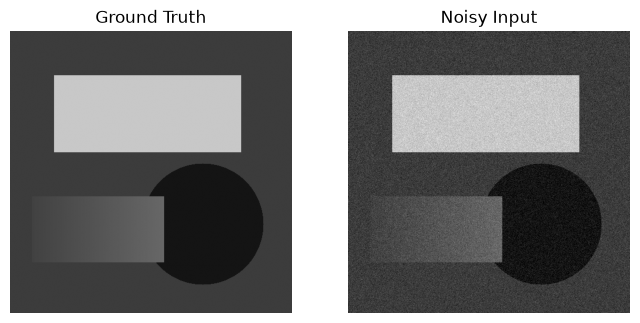

In [3]:
img = np.asarray(Image.open("A2\\Q1,4\\q4.png").convert("L"), dtype=float) / 255

rng = np.random.default_rng(42)
sigma = 0.05
clean = img
noisy = np.clip(clean + rng.normal(0, sigma, clean.shape), 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, im, title in zip(ax, [clean, noisy], ["Ground Truth", "Noisy Input"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=1)
    a.set_title(title)
    a.axis("off")
plt.show()

chosen sigma = 0.05

In [4]:

def bilateral(img, sigma_s, sigma_r, radius=3):
    k = 2 * radius + 1
    padded = np.pad(img, radius, mode="reflect")
    windows = sliding_window_view(padded, (k, k))

    y, x = np.mgrid[-radius:radius+1, -radius:radius+1]
    spatial = np.exp(-(x**2 + y**2) / (2 * sigma_s**2))

    range_w = np.exp(-(windows - img[:, :, None, None])**2 / (2 * sigma_r**2))
    weights = spatial * range_w

    return np.sum(weights * windows, axis=(-2, -1)) / np.sum(weights, axis=(-2, -1))


In [5]:

def kuwahara(img, radius=3):
    k = 2 * radius + 1
    padded = np.pad(img, radius, mode="reflect")
    windows = sliding_window_view(padded, (k, k))

    regions = [
        windows[..., :radius+1, :radius+1],
        windows[..., :radius+1, radius:],
        windows[..., radius:, :radius+1],
        windows[..., radius:, radius:]
    ]

    means = np.stack([r.mean(axis=(-2, -1)) for r in regions])
    variances = np.stack([r.var(axis=(-2, -1)) for r in regions])

    return np.take_along_axis(means, variances.argmin(axis=0)[None, ...], axis=0)[0]



### 4.1 Matched Smoothing Strength

Both filters use a $7\times7$ neighborhood to match their spatial footprints.

To match effective smoothing, we compare their variance reduction in a flat region $R$:

$$
\rho=\frac{\operatorname{Var}(\hat I_R)}
{\operatorname{Var}(I_{\text{noisy},R})}
$$

We fix the bilateral range parameter $\sigma_r=0.15$ and select $\sigma_s$ to minimize

$$
|\rho_{\text{bilateral}}-\rho_{\text{Kuwahara}}|
$$

This matches the empirical noise suppression of both filters rather than comparing only their window sizes.


In [6]:
R = np.s_[5:25, 5:25]

kuw = kuwahara(noisy)
rho_k = np.var(kuw[R]) / np.var(noisy[R])

candidates = np.linspace(0.8, 3.0, 12)
sigma_r = 0.15

results = []
for s in candidates:
    out = bilateral(noisy, s, sigma_r)
    rho_b = np.var(out[R]) / np.var(noisy[R])
    results.append(abs(rho_b - rho_k))

sigma_s = candidates[np.argmin(results)]
bil = bilateral(noisy, sigma_s, sigma_r)

print(f"Kuwahara variance ratio: {rho_k:.4f}")
print(f"Bilateral variance ratio: {np.var(bil[R]) / np.var(noisy[R]):.4f}")
print(f"Selected sigma_s: {sigma_s:.2f}")


Kuwahara variance ratio: 0.0529
Bilateral variance ratio: 0.0578
Selected sigma_s: 1.40


In [7]:

print(f"{'Method':<15} {'PSNR (dB)':>12} {'SSIM':>10}")

for name, im in [("Noisy", noisy), ("Bilateral", bil), ("Kuwahara", kuw)]:
    psnr = my_psnr(clean, im)
    ssim = my_ssim(clean, im)
    print(f"{name:<15} {psnr:>12.3f} {ssim:>10.4f}")


Method             PSNR (dB)       SSIM
Noisy                 26.063     0.3022
Bilateral             37.572     0.8799
Kuwahara              37.520     0.8782


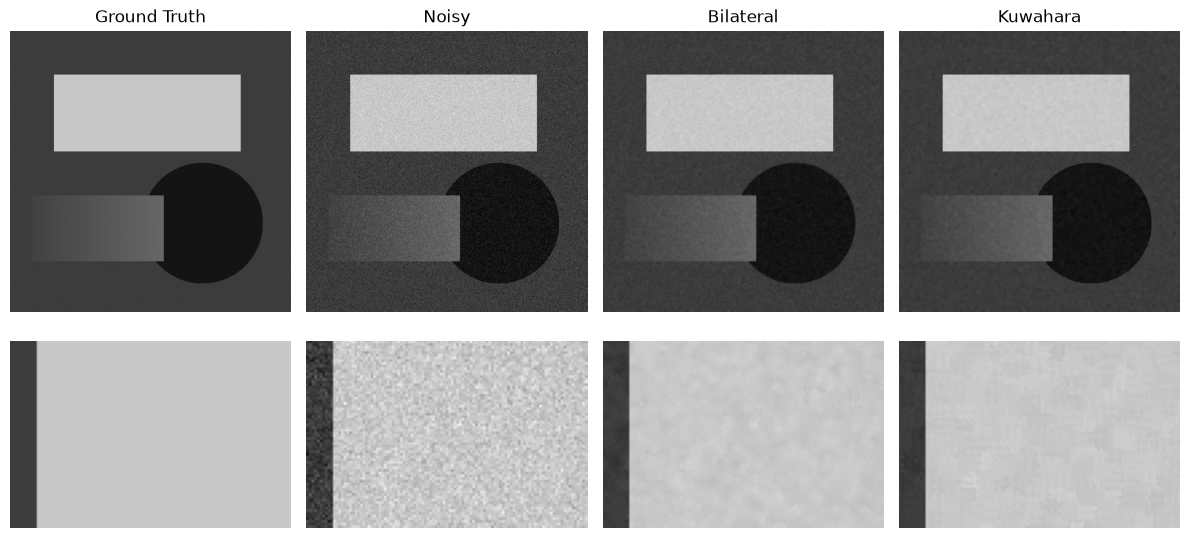

In [8]:
images = [clean, noisy, bil, kuw]
titles = ["Ground Truth", "Noisy", "Bilateral", "Kuwahara"]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, (im, title) in enumerate(zip(images, titles)):
    axes[0, i].imshow(im, cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(title)

    axes[1, i].imshow(im[100:170, 70:175], cmap="gray", vmin=0, vmax=1)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()



### 4.1
- Both filters significantly improve PSNR and SSIM compared to the noisy input.
- The bilateral filter achieves slightly higher PSNR and SSIM at approximately matched smoothing strength.
- Both filters preserve the sharp region boundaries, but Kuwahara introduces subtle patch-like variations due to its discrete minimum-variance sub-window selection.
- The cropped comparison shows smoother intensity transitions with bilateral filtering, while Kuwahara produces a slightly more blocky appearance.

**Conclusion:** Both filters provide comparable denoising and edge preservation at matched strength. Bilateral filtering performs marginally better quantitatively and produces smoother visual results.


### 4.2(a) Mechanism of Kuwahara Blockiness

The classical Kuwahara filter selects the mean of the minimum-variance sub-window:

$$
I_{\text{out}}(p)=\mu_{k^*}(p), \qquad
k^*=\arg\min_k \sigma_k^2(p)
$$

The hard `argmin` selection is discontinuous. Small changes in the sub-window variances between neighboring pixels can cause the selected region to switch abruptly, producing discontinuities in the output.

Larger windows average over larger regions, making these discontinuities appear as blocky. Unlike blur or ringing, this artifact results from discrete region selection.

In [9]:

def soft_kuwahara(img, radius=5, beta=500):
    k = 2 * radius + 1
    padded = np.pad(img, radius, mode="reflect")
    windows = sliding_window_view(padded, (k, k))

    regions = [
        windows[..., :radius+1, :radius+1],
        windows[..., :radius+1, radius:],
        windows[..., radius:, :radius+1],
        windows[..., radius:, radius:]
    ]

    means = np.stack([r.mean(axis=(-2, -1)) for r in regions])
    variances = np.stack([r.var(axis=(-2, -1)) for r in regions])

    weights = np.exp(-beta * (variances - variances.min(axis=0)))
    return np.sum(weights * means, axis=0) / np.sum(weights, axis=0)


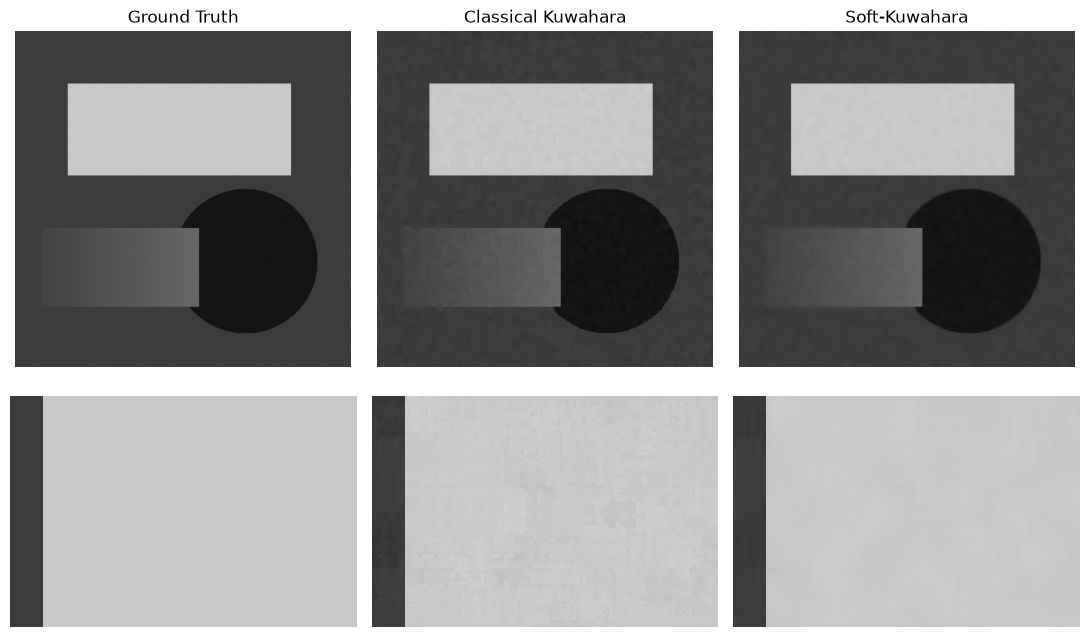

In [10]:

radius = 5

kw_classic = kuwahara(noisy, radius)
kw_soft = soft_kuwahara(noisy, radius, beta=500)

fig, axes = plt.subplots(2, 3, figsize=(11, 7))

images = [clean, kw_classic, kw_soft]
titles = ["Ground Truth", "Classical Kuwahara", "Soft-Kuwahara"]

for i, (im, title) in enumerate(zip(images, titles)):
    axes[0, i].imshow(im, cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(title)
    axes[1, i].imshow(im[100:170, 70:175], cmap="gray", vmin=0, vmax=1)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [11]:

def total_variation(im):
    return np.abs(np.diff(im, axis=0)).sum() + np.abs(np.diff(im, axis=1)).sum()

R = np.s_[5:40, 5:40]  # Flat background region

print(f"{'Method':<20} {'PSNR':>10} {'SSIM':>10} {'Total Variation (flat)':>25}")

for name, im in [("Classic", kw_classic), ("Soft-Kuwahara", kw_soft)]:
    psnr = my_psnr(clean, im)
    ssim = my_ssim(clean, im)
    tv = total_variation(im[R])
    print(f"{name:<20} {psnr:>10.3f} {ssim:>10.4f} {tv:>12.3f}")


Method                     PSNR       SSIM    Total Variation (flat)
Classic                  40.620     0.9460       12.797
Soft-Kuwahara            43.360     0.9839        5.417



### 4.2(c) Per-Pixel Computational Complexity
### 4.2(c) Per-Pixel Computational Complexity



| Operation | Bilateral | Classical Kuwahara | Soft Kuwahara |
| :--- | :--- | :--- | :--- |
| Additions/subtractions | $O(k^2)$ | $O(4m)$ | $O(4m)$ |
| Multiplications | $O(k^2)$ | $O(4m)$ | $O(4m)$ |
| Exponentials | $k^2$ range weights | 0 | 4 |
| Variance calculations | No | 4 | 4 |

For the 7×7 neighborhood used in Section 4.1, \(k=7\) and \(m=16\):

| Operation | Bilateral | Classical Kuwahara | Soft-Kuwahara |
|---|---:|---:|---:|
| Additions/subtractions | 145 | 184 | 191 |
| Multiplications | 196 | 64 | 68 |
| Exponentials | 49 | 0 | 4 |

- The assymptotic time complexity Hence overall per pixel complexity is $O(N^2)$ for all 3 methods
- **Most expensive:** Bilateral filtering, because it evaluates approximately $N^2$ range-kernel exponentials per pixel, compared with only four for Soft-Kuwahara and none for Classical Kuwahara.

Note: If spatial Gaussian weights are not precomputed, bilateral filtering additionally requires spatial-weight exponentials. But they can be precomputed once per function call, so they should not be counted as per-pixel exponentials

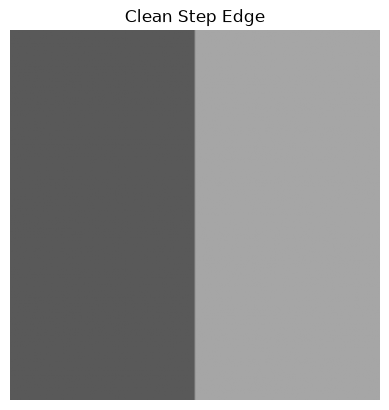

In [12]:
size = 128
I1, I2 = 0.35, 0.65
delta = I2 - I1

step = np.full((size, size), I1)
step[:, size//2:] = I2

plt.imshow(step, cmap="gray", vmin=0, vmax=1)
plt.title("Clean Step Edge")
plt.axis("off")
plt.show()


In [13]:
ncr_values = np.linspace(0.05, 2.0, 30)
rng = np.random.default_rng(42)
edge_scores = []

for ncr in ncr_values:
    sigma = ncr * delta
    scores = []

    for _ in range(5):
        noisy_step = step + rng.normal(0, sigma, step.shape)
        filtered = bilateral(noisy_step, sigma_s=1.4, sigma_r=2*sigma)

        m = size // 2
        score = abs(filtered[:, m].mean() - filtered[:, m-1].mean()) / delta
        scores.append(score)

    edge_scores.append(np.mean(scores))

edge_scores = np.array(edge_scores)

idx = np.where(edge_scores < 0.8)[0]
ncr_star = ncr_values[idx[0]] if len(idx) else None

print(f"Critical NCR*: {ncr_star if ncr_star is not None else 'Not reached'}")


Critical NCR*: 0.2517241379310345


The actual observed intensity difference across the edge is $\Delta I + \epsilon_1 - \epsilon_2$, where $\epsilon_1 - \epsilon_2$ has variance $2\sigma_{\text{noise}}^2$. Thus, the clean-step range-weight formula is an approximation; the measured breakdown also depends on random noise fluctuations.

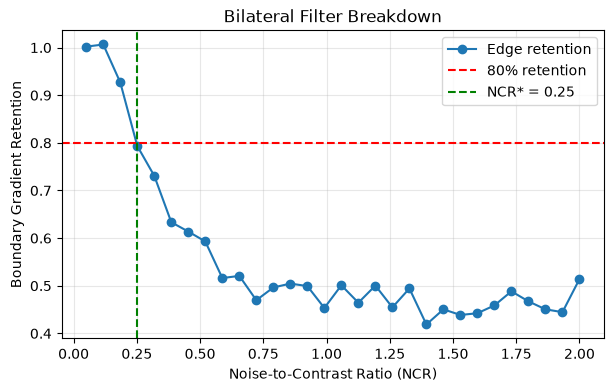

In [14]:

plt.figure(figsize=(7, 4))
plt.plot(ncr_values, edge_scores, "o-", label="Edge retention")
plt.axhline(0.8, color="red", linestyle="--", label="80% retention")

if ncr_star is not None:
    plt.axvline(ncr_star, color="green", linestyle="--",
                label=f"NCR* = {ncr_star:.2f}")

plt.xlabel("Noise-to-Contrast Ratio (NCR)")
plt.ylabel("Boundary Gradient Retention")
plt.title("Bilateral Filter Breakdown")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### Observations
- At low NCR, boundary gradient retention remains close to 1, indicating effective edge preservation.
- Near $NCR=0.252$, retention falls below the defined 80% threshold, marking the onset of significant cross-boundary smoothing.
- At higher NCR, retention approaches approximately 0.5, indicating substantial loss of boundary sharpness.


### 4.3 Bilateral Filter Breakdown

A synthetic $128\times128$ step-edge image was generated with intensities $I_1=0.35$ and $I_2=0.65$, giving $|\Delta I|=0.30$. Independent zero-mean Gaussian noise was added across different NCR values.

$$NCR=\frac{\sigma_{\text{noise}}}{|\Delta I|}$$

**Edge preservation metric:**

$$E=\frac{|\bar I_{\text{out}}(m)-\bar I_{\text{out}}(m-1)|}{|\Delta I|}$$

The empirical critical threshold $NCR^*$ is defined as the first tested NCR where $E<0.8$, indicating more than 20% loss of the original boundary gradient.

**Mathematical explanation:**

The bilateral range weight is

$$w_r(\Delta I)=\exp\left(-\frac{\Delta I^2}{2\sigma_r^2}\right)$$

Using $\sigma_r=2\sigma_{\text{noise}}$ gives

$$w_r(\Delta I)=\exp\left(-\frac{1}{8NCR^2}\right)$$

At low NCR, the range kernel strongly suppresses cross-boundary averaging. As NCR increases, noisy intensity distributions overlap and the cross-edge weights increase, causing bilateral filtering to smooth across the boundary.

The critical threshold is empirical and depends on the filter parameters and the chosen edge-retention criterion.
